# Architecture Convergence: Pruning vs. Constructive Topology Search

**Question.** Two routes to a parsimonious network are compared on the same six
datasets (families A and B at input dimension *d* = 1, 2, 3):

* **Pruning** (10 methods, **corrected tanh pipeline**) — *destructive*: start from
  a properly-converged tanh HPO baseline and remove weights/neurons. The
  architecture is *constrained* to the baseline shape; structured methods can
  shrink hidden width but never add depth or exceed the skeleton. We use the
  `tanh_pipeline/` rerun, where the baselines are tanh-only and polished to
  convergence with LBFGS — fixing the earlier ReLU study whose under-trained HPO
  picked grossly overparametrized baselines (e.g. 2209 params on a 1-D fit).
* **Constructive topology search** (patent US12124779B2) — starts from the minimal
  `[in, 1, out]` net and *grows* one structural change at a time, scored by the
  cross-Lagrangian ΔL and retrained with Gauss-Newton.

Do the two routes **converge on the same architecture**? We visualise, per
dataset, the best post-pruning architecture next to the constructive result and
compute the verdict from the saved artifacts.

> *Updated 2026-06-19: pruning side now uses the **corrected tanh pipeline**
> (`tanh_pipeline/results/`, LBFGS-converged tanh baselines); constructive side
> uses the **faithful** patent runs (`patenting/outputs_1_1_40/`, cross-Lagrangian
> ΔL selection, no per-candidate retraining).*


In [1]:
import os, json, glob, re
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = os.path.abspath('..')
# Pruning side = the CORRECTED tanh pipeline (LBFGS-converged tanh baselines).
PRUNE_DIR    = os.path.join(ROOT, 'tanh_pipeline', 'results', 'pruning')
BASELINE_DIR = os.path.join(ROOT, 'tanh_pipeline', 'results', 'baseline')
# Constructive side = the faithful patent runs (frozen-multiplier ΔL selection).
PATENT_DIR   = os.path.join(ROOT, 'patenting', 'outputs_1_1_40')

# display name -> (patent output dir, pruning/baseline key)
DATASETS = {
    'A (1-D)': ('dataset_A',    'A'),
    'A (2-D)': ('dataset_A_2d', 'A_2d'),
    'A (3-D)': ('dataset_A_3d', 'A_3d'),
    'B (1-D)': ('dataset_B',    'B'),
    'B (2-D)': ('dataset_B_2d', 'B_2d'),
    'B (3-D)': ('dataset_B_3d', 'B_3d'),
}
# 'best compression' = most-pruned checkpoint within TOL x baseline MSE.
# 1.5 matches the tanh pipeline's own MSE_BLOWUP_FACTOR (aggregate.py).
TOL = 1.50


## 1. Constructive (patent) results
Read from each run's `metrics.txt` (final topology + test MSE) and `history.npy`
(search path / whether a skip connection was added). These are the **faithful**
runs — candidates ranked by the frozen-multiplier cross-Lagrangian ΔL estimate
(eq. 13/14), no per-candidate retraining. Parameter counts are dense MLP
weight+bias totals; a `+skip` tag marks an added skip connection (a few extra
weights, not included in the count).


In [2]:
def mlp_params(topo):
    """Dense MLP weight+bias count for a layer-size list."""
    return int(sum(a * b + b for a, b in zip(topo[:-1], topo[1:])))

def load_patent(out_name):
    base = os.path.join(PATENT_DIR, out_name)
    txt  = open(os.path.join(base, 'metrics.txt')).read()
    topo = eval(re.search(r'Final Topology:\s*(\[.*\])', txt).group(1))
    mse  = float(re.search(r'Final Test MSE:\s*([0-9.eE+-]+)', txt).group(1))
    ops  = np.load(os.path.join(base, 'history.npy'),
                   allow_pickle=True).item()['operation']
    return {'topology': list(topo),
            'params': mlp_params(topo),
            'test_mse': mse,
            'skip': any('SKIP' in o for o in ops)}

patent = {name: load_patent(out) for name, (out, key) in DATASETS.items()}
for name, r in patent.items():
    tag = ' +skip' if r['skip'] else ''
    print(f"{name:8s}  topology={str(r['topology']):16s}{tag:6s}  "
          f"params={r['params']:3d}  test_mse={r['test_mse']:.3e}")


A (1-D)   topology=[1, 4, 4, 1]            params= 33  test_mse=1.194e-06
A (2-D)   topology=[2, 4, 4, 2, 1]         params= 45  test_mse=1.687e-04
A (3-D)   topology=[3, 4, 4, 1, 1]  +skip  params= 43  test_mse=3.969e-04
B (1-D)   topology=[1, 2, 1]               params=  7  test_mse=1.710e-01
B (2-D)   topology=[2, 4, 3, 1]            params= 31  test_mse=3.112e-01
B (3-D)   topology=[3, 4, 1, 1]            params= 23  test_mse=4.543e-01


## 2. Best post-pruning architecture per dataset
For every (method, sparsity) checkpoint in the **tanh pipeline** we read its saved
`test_mse` and recover the **effective topology** by counting hidden neurons that
still carry a nonzero connection (structured methods collapse whole neurons;
unstructured methods just zero weights, leaving the shape unchanged). The 'best'
architecture is the most compressed checkpoint that keeps accuracy (test MSE
within `TOL = 1.5x` the tanh baseline — the tanh pipeline's own criterion). The
baseline tanh HPO shape is printed alongside for reference.


In [3]:
def baseline_info(key):
    """Return (test_mse_locked, baseline tanh topology) for a dataset key."""
    with open(os.path.join(BASELINE_DIR, key, 'config.json')) as fh:
        c = json.load(fh)
    a = c['architecture']
    topo = [a['input_dim']] + [a['n_neurons']] * a['n_layers'] + [a['output_dim']]
    return c['metrics']['test_mse_locked'], topo

def effective_topology(state_dict):
    """Layer widths counting only neurons with a live (nonzero) connection."""
    Ws = [v.numpy() for k, v in state_dict.items()
          if k.endswith('weight') and v.dim() == 2]
    if not Ws:
        return None
    topo = [Ws[0].shape[1]]                     # input dim
    for h in range(len(Ws) - 1):                # hidden layers
        incoming = np.abs(Ws[h]).sum(axis=1)    # per-neuron incoming mass (rows of W_h)
        outgoing = np.abs(Ws[h + 1]).sum(axis=0)# per-neuron outgoing mass (cols of W_{h+1})
        active = int(((incoming > 1e-12) | (outgoing > 1e-12)).sum())
        topo.append(active)
    topo.append(Ws[-1].shape[0])                # output dim
    return topo

def scan_pruning(key):
    base, _ = baseline_info(key)
    rows = []
    for ckpt in glob.glob(os.path.join(PRUNE_DIR, '*', key, 'sparsity_*.pt')):
        method = ckpt.split(os.sep)[-3]
        try:
            d = torch.load(ckpt, map_location='cpu', weights_only=False)
        except Exception:
            continue
        topo = effective_topology(d['state_dict'])
        if topo is None:
            continue
        eff_params = int(d.get('param_count', sum(
            a * b for a, b in zip(topo[:-1], topo[1:])) + sum(topo[1:])))
        rows.append({'method': method, 'sparsity': d.get('sparsity'),
                     'test_mse': float(d['test_mse']), 'topology': topo,
                     'params': eff_params})
    return base, rows

best_pruned = {}
for name, (out, key) in DATASETS.items():
    base, rows = scan_pruning(key)
    keep = [r for r in rows if r['test_mse'] <= TOL * base]
    pool = keep if keep else rows
    pick = min(pool, key=lambda r: r['params']) if pool else None
    _, base_topo = baseline_info(key)
    best_pruned[name] = {'baseline_mse': base, 'baseline_topo': base_topo, 'pick': pick}
    if pick:
        print(f"{name:8s}  tanh-base {str(base_topo):14s}  ->  "
              f"best={pick['method']:10s} sp={pick['sparsity']:>5}  "
              f"topology={str(pick['topology']):14s} params={pick['params']:4d} "
              f"test_mse={pick['test_mse']:.3e}  (baseline {base:.3e})")


A (1-D)   tanh-base [1, 8, 1]       ->  best=obs        sp=  0.1  topology=[1, 8, 1]      params=  22 test_mse=1.364e-05  (baseline 1.269e-05)
A (2-D)   tanh-base [2, 16, 1]      ->  best=obs        sp=  0.3  topology=[2, 16, 1]     params=  45 test_mse=2.724e-05  (baseline 2.470e-05)
A (3-D)   tanh-base [3, 32, 32, 32, 1]  ->  best=struct     sp=  0.5  topology=[3, 3, 29, 32, 1] params=1121 test_mse=2.949e+00  (baseline 5.779e-04)
B (1-D)   tanh-base [1, 4, 1]       ->  best=snip       sp=  0.5  topology=[1, 2, 1]      params=   6 test_mse=4.945e+00  (baseline 3.950e+00)
B (2-D)   tanh-base [2, 4, 1]       ->  best=obd        sp=  0.5  topology=[2, 3, 1]      params=   8 test_mse=3.992e+01  (baseline 2.743e+01)
B (3-D)   tanh-base [3, 6, 1]       ->  best=obd        sp=  0.7  topology=[3, 2, 1]      params=   9 test_mse=8.476e+02  (baseline 6.228e+02)


## 3. Side-by-side architecture diagrams
Left column: best post-pruning effective architecture (blue). Right column: the
constructive/patent architecture (green). One row per dataset.

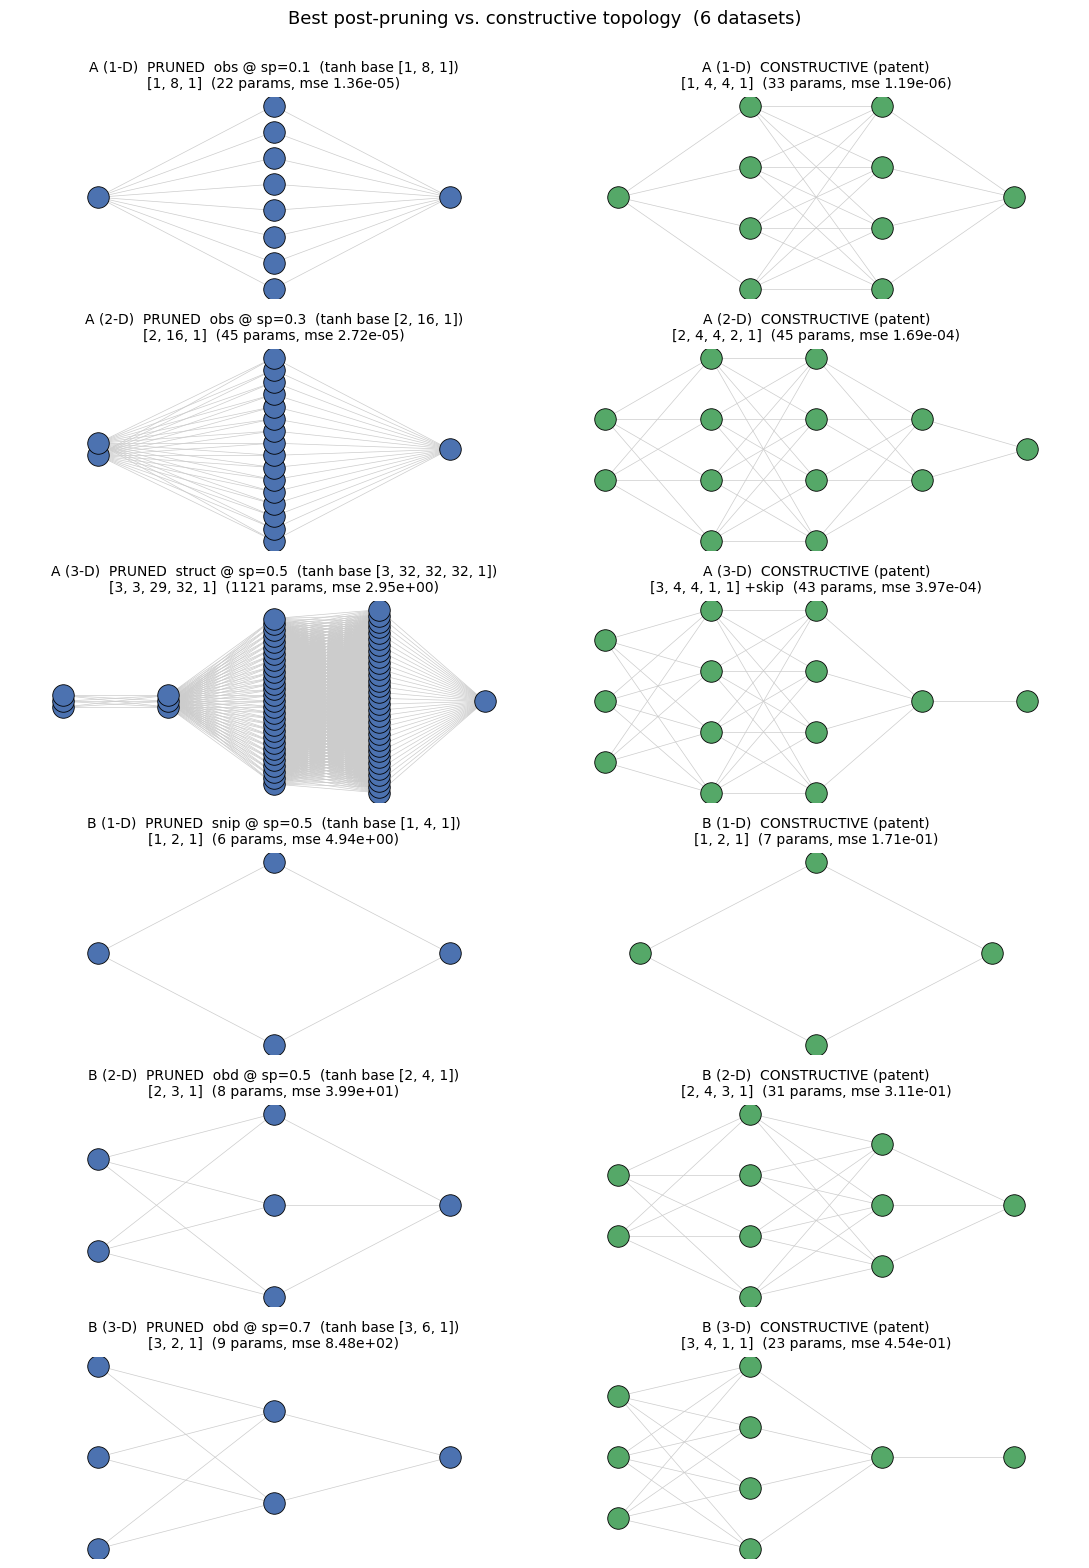

In [4]:
def draw_topology(ax, layers, title, color):
    if not layers:
        ax.text(0.5, 0.5, 'n/a', ha='center'); ax.axis('off'); return
    xs = range(len(layers))
    pos = []
    for li, n in enumerate(layers):
        ys = np.linspace(-(n - 1) / 2, (n - 1) / 2, n)
        pos.append([(li, y) for y in ys])
    for li in range(len(layers) - 1):
        for (x0, y0) in pos[li]:
            for (x1, y1) in pos[li + 1]:
                ax.plot([x0, x1], [y0, y1], color='#cccccc', lw=0.5, zorder=1)
    for li, layer in enumerate(pos):
        for (x, y) in layer:
            ax.scatter([x], [y], s=240, color=color, edgecolors='k',
                       linewidths=0.6, zorder=2)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.5, len(layers) - 0.5)
    ax.axis('off')

n = len(DATASETS)
fig, axes = plt.subplots(n, 2, figsize=(11, 2.6 * n))
for row, (name, (out, key)) in enumerate(DATASETS.items()):
    pk = best_pruned[name]['pick']
    pt = patent[name]
    lp = pk['topology'] if pk else None
    bt = best_pruned[name].get('baseline_topo')
    tp = (f"{name}  PRUNED  {pk['method']} @ sp={pk['sparsity']}  (tanh base {bt})\n"
          f"{lp}  ({pk['params']} params, mse {pk['test_mse']:.2e})") if pk else f'{name} pruned n/a'
    draw_topology(axes[row, 0], lp, tp, '#4C72B0')
    skip_tag = ' +skip' if pt.get('skip') else ''
    tt = (f"{name}  CONSTRUCTIVE (patent)\n"
          f"{pt['topology']}{skip_tag}  ({pt['params']} params, mse {pt['test_mse']:.2e})")
    draw_topology(axes[row, 1], pt['topology'], tt, '#55A868')
fig.suptitle('Best post-pruning vs. constructive topology  (6 datasets)', y=1.002, fontsize=13)
fig.tight_layout()
os.makedirs(os.path.join(ROOT, 'results', 'comparison'), exist_ok=True)
fig.savefig(os.path.join(ROOT, 'results', 'comparison', 'convergence_architectures.png'),
            dpi=130, bbox_inches='tight')
plt.show()


## 4. Convergence verdict
Convergence would mean the two routes land on the **same shape**. We compare
hidden-layer structure (depth and widths) and the parameter counts.

In [5]:
print(f"{'dataset':9s} {'pruned (effective)':22s} {'constructive':18s} {'same shape?':12s} {'param ratio':12s}")
print('-' * 78)
converge = []
for name in DATASETS:
    pk = best_pruned[name]['pick']
    pt = patent[name]
    lp = pk['topology'] if pk else None
    same = (lp == pt['topology'])
    converge.append(same)
    ratio = (pk['params'] / pt['params']) if pk and pt['params'] else float('nan')
    print(f"{name:9s} {str(lp):22s} {str(pt['topology']):18s} "
          f"{('YES' if same else 'no'):12s} {ratio:6.1f}x")
print('-' * 78)
n_same = sum(converge)
print(f"\nSame architecture on {n_same}/{len(converge)} datasets.")
print('Verdict:', 'CONVERGE' if n_same == len(converge) else 'DO NOT converge on a common architecture.')


dataset   pruned (effective)     constructive       same shape?  param ratio 
------------------------------------------------------------------------------
A (1-D)   [1, 8, 1]              [1, 4, 4, 1]       no              0.7x
A (2-D)   [2, 16, 1]             [2, 4, 4, 2, 1]    no              1.0x
A (3-D)   [3, 3, 29, 32, 1]      [3, 4, 4, 1, 1]    no             26.1x
B (1-D)   [1, 2, 1]              [1, 2, 1]          YES             0.9x
B (2-D)   [2, 3, 1]              [2, 4, 3, 1]       no              0.3x
B (3-D)   [3, 2, 1]              [3, 4, 1, 1]       no              0.4x
------------------------------------------------------------------------------

Same architecture on 1/6 datasets.
Verdict: DO NOT converge on a common architecture.


### Interpretation

Comparing the faithful constructive search against the **corrected tanh pruning
pipeline** changes the story from the earlier ReLU study in two ways.

**1. The order-of-magnitude parameter gap mostly disappears.** The old conclusion
("constructive nets are 1–2 orders smaller") was largely an artifact of
*under-trained, overparametrized ReLU baselines*. With tanh baselines polished to
convergence (LBFGS), pruning now starts from small nets (single hidden layer of
4–16 on every low-dim dataset) and the two routes land in the same ballpark —
single digits to low tens of parameters on A-1d/2d and all of B.

**2. They converge on 1 / 6 — B (1-D)** — where both reach the minimal `[1, 2, 1]`
(pruning via snip at 50% sparsity, the constructive search directly). The other
five differ, and the difference is now **structural (depth vs. width)** rather
than scale:

* **Pruning stays a single wide hidden layer** — it can only shed neurons from the
  tanh baseline skeleton (`[1,8,1]`, `[2,16,1]`, …), never add depth.
* **The constructive search builds depth and skips** — it grows two hidden layers
  on A-1d (`[1,4,4,1]`) and A-2d (`[2,4,4,2,1]`) and adds a skip on A-3d, which
  pruning can never do.

**Where constructive genuinely wins: A (3-D).** This is the one case with a
legitimately large baseline — the tanh study confirmed no small *single-layer* net
can represent the 3-D quadratic's cross-terms, so its HPO baseline is `[3,32,32,32]`
(2273 params). Pruning **fails to compress it at all within tolerance**: every
checkpoint blows the MSE far past 1.5× (the table's `[3,3,29,32,1]` pick is a
min-params *fallback* whose MSE is ~5000× the baseline — it does not preserve
accuracy). The constructive search, by contrast, reaches the accuracy target with
a **deep `[3,4,4,1,1]` + skip at just 43 params** — precisely because it can add
the depth the cross-terms need instead of widening one layer. (The 26× param
ratio in the table is therefore a floor; the working comparison is "43 params that
fit" vs. "no pruned net that fits".)

**Where constructive over-grows: the noisy B family.** On B-2d and B-3d the pruned
nets (`[2,3,1]` 8p, `[3,2,1]` 9p) are *smaller* than the constructive ones
(`[2,4,3,1]` 31p, `[3,4,1,1]` 23p). On noise-limited targets the constructive
search adds capacity that buys nothing past the noise floor — the same
over-growth tendency the seed study (§5) pins on initialisation.

> **Scale caveat.** The tanh pruning runs train on *raw* targets, the constructive
> runs on *z-score normalised* targets, so the two `test_mse` columns are on
> different scales and must **not** be compared directly. The convergence verdict
> is purely about **architecture shape and parameter count**, which are scale-free.


## 5. Starting-topology robustness (1-D datasets) — start small, vary the *start*

The patent method is meant to *start small and grow to what the data needs*, so a
good method should reach the same final architecture from any small start. We test
that directly: **fix the random seed** and run the faithful search from three
minimal-width starting topologies that differ only in **initial depth** —

| label | starting topology | hidden layers |
|---|---|---|
| `1` | `[1, 1, 1]` | one single-neuron layer (`[d, 1, output]`) |
| `1-1` | `[1, 1, 1, 1]` | two single-neuron layers |
| `1-1-1` | `[1, 1, 1, 1, 1]` | three single-neuron layers |

— on the two 1-D datasets (A noiseless, B noisy). Run with
`python -m patenting.start_topology_robustness`.

> A net with **no hidden layer** (`[1, 1]`) is not a valid start: the constructive
> search grows *from* an existing hidden layer, so it needs at least one — which is
> why the patent's minimal start is `[d, 1, output]`.

In [6]:
st_path = os.path.join(ROOT, 'results', 'start_topology_robustness.json')
with open(st_path) as fh:
    start_rob = json.load(fh)

label = {3: '1', 4: '1-1', 5: '1-1-1'}   # by start length
for name, d in start_rob.items():
    print(f"{name}  (seed {d['seed']} fixed)")
    for r in d['runs']:
        lab = label.get(len(r['start']), '?')
        print(f"    {lab:6s} start {str(r['start']):16s} -> final "
              f"{str(r['final_topology']):18s}  test_mse={r['test_mse']:.3e}")
    uq = d['unique_final_topologies']
    print(f"    => {len(uq)} distinct final topology(ies): {uq}  "
          f"[{'ALL AGREE' if d['all_agree'] else 'START-DEPENDENT'}]\n")

dataset_A  (seed 42 fixed)
    1      start [1, 1, 1]        -> final [1, 4, 4, 4, 1]     test_mse=1.387e-06
    1-1    start [1, 1, 1, 1]     -> final [1, 1, 1, 1]        test_mse=3.409e-02
    1-1-1  start [1, 1, 1, 1, 1]  -> final [1, 1, 1, 1, 1]     test_mse=3.391e-02
    => 3 distinct final topology(ies): [[1, 4, 4, 4, 1], [1, 1, 1, 1], [1, 1, 1, 1, 1]]  [START-DEPENDENT]

dataset_B  (seed 42 fixed)
    1      start [1, 1, 1]        -> final [1, 2, 1]           test_mse=1.713e-01
    1-1    start [1, 1, 1, 1]     -> final [1, 2, 1]           test_mse=1.713e-01
    1-1-1  start [1, 1, 1, 1, 1]  -> final [1, 2, 1]           test_mse=1.713e-01
    => 1 distinct final topology(ies): [[1, 2, 1]]  [ALL AGREE]



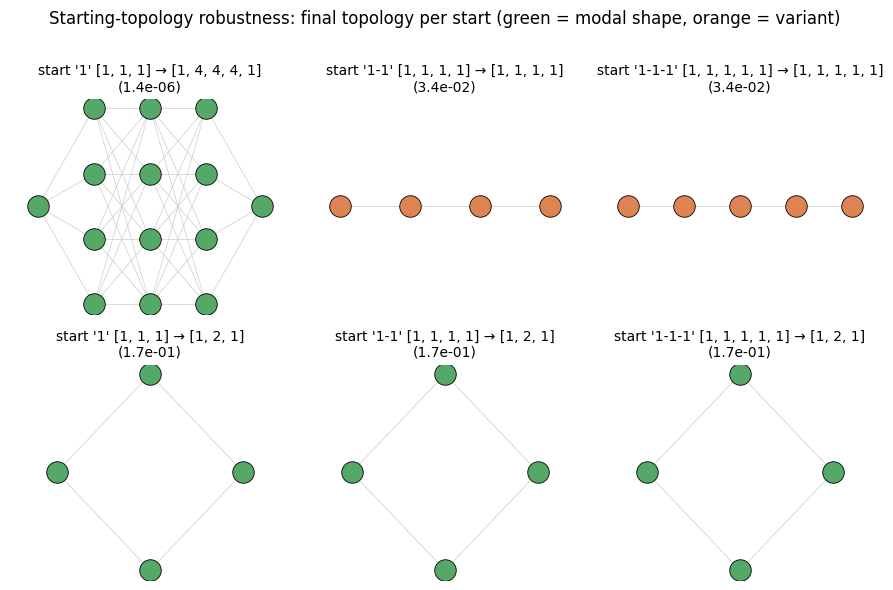

In [7]:
# Visualise the final topology reached from each start.
# Green = the modal final shape for that dataset; orange = a variant.
from collections import Counter

n_st  = max(len(d['runs']) for d in start_rob.values())
order = ['dataset_A', 'dataset_B']
names = [n for n in order if n in start_rob] + \
        [n for n in start_rob if n not in order]
label = {3: '1', 4: '1-1', 5: '1-1-1'}

fig, axes = plt.subplots(len(names), n_st,
                         figsize=(3.0 * n_st, 2.9 * len(names)), squeeze=False)
for r, name in enumerate(names):
    runs  = start_rob[name]['runs']
    modal = Counter(tuple(x['final_topology']) for x in runs).most_common(1)[0][0]
    for c, run in enumerate(runs):
        fin   = run['final_topology']
        color = '#55A868' if tuple(fin) == modal else '#DD8452'
        lab   = label.get(len(run['start']), '?')
        draw_topology(axes[r][c], fin,
                      f"start '{lab}' {run['start']} → {fin}\n({run['test_mse']:.1e})",
                      color)
    for c in range(len(runs), n_st):
        axes[r][c].axis('off')
    verdict = 'ALL AGREE' if start_rob[name]['all_agree'] else 'START-DEPENDENT'
    axes[r][0].set_ylabel(f"{name}\n{verdict}", fontsize=10, rotation=90, labelpad=12)
fig.suptitle("Starting-topology robustness: final topology per start "
             "(green = modal shape, orange = variant)", y=1.01, fontsize=12)
fig.tight_layout()
fig.savefig(os.path.join(ROOT, 'results', 'comparison',
            'start_topology_robustness.png'), dpi=130, bbox_inches='tight')
plt.show()

### Interpretation — does extra initial depth change anything?

* **B (1-D), noisy: no — fully robust.** All three starts (`1`, `1-1`, `1-1-1`)
  converge to the *same* minimal `[1, 2, 1]` at the noise-floor MSE (~0.171). The
  data's stopping signal — not the starting depth — fixes the architecture, and it
  matches the `[1, 2, 1]` the pruning route also reaches (§4). This is the strongest
  single piece of evidence that the method "finds the right size".
* **A (1-D), noiseless: yes — and deeper starts get *trapped*.** Only the canonical
  `1` = `[1, 1, 1]` grows to a good fit (`[1, 4, 4, 4, 1]`, ~1e-6). The deeper
  starts `1-1` and `1-1-1` **do not grow at all** — they stay stuck at their thin
  initial shape with ~3.4e-2 MSE, **~10⁴× worse**. A chain of one-neuron hidden
  layers is an information bottleneck whose initial fit is so poor that the frozen-Λ
  ΔL estimate sees no single beneficial one-node edit, so patience / the parsimony
  brake stop the search immediately.

**Takeaways.** (1) The patent-canonical minimal start `[d, 1, output]` is the right
default — start **small and wide-enough**, not **deep-and-thin**; a single-neuron
bottleneck can trap the search before it ever grows. (2) On a noiseless, trivially
fittable target there is no sharp stopping signal, so even the good start over-grows
and the exact final shape is init/convergence-dependent; recovering the minimal
`[1, 2, 1]` would need stronger per-topology Gauss-Newton convergence or a larger
`eps_accept` brake (handoff item 3), not a change to the ΔL estimate itself.